In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#open data file
data = pd.read_csv('../data/Metro_Interstate_Traffic_Volume.csv')
columns = ['temp', 'rain_1h', 'snow_1h', 'date_time', 'traffic_volume']
X = data[columns]

In [ ]:
data['date_time'] = pd.to_datetime(data['date_time'])
# sorting the temp column in terms of date time 
data = data.sort_values('date_time').reset_index(drop=True)
data.loc[data['temp'] == 0, 'temp'] = np.nan
data['temp'] = data['temp'].interpolate()

print(data['temp'].isna().sum())
print(data['temp'].min())

#quickly converting to F for readability
data['temp_f'] = (data['temp'] - 273.15) * 9/5 + 32

0
243.39


*replaced temp = 0K values with linear interpolation after sorting by time new min is 243.39K*

In [ ]:

#our data has a gap from august 2014 to june 2015 307 days
gaps = data['date_time'].diff()
data.loc[gaps.idxmax(), 'date_time'], gaps.max()

#we're gonna check for duped timestamps next
dupes = data[data['date_time'].duplicated(keep=False)]
dupes.head(10)

#we found some dupes so now we gotta remove them by keeping one row per timestamp
before = len(data)
data = data.drop_duplicates(subset='date_time', keep='first').reset_index(drop=True)
print(before - len(data), 'duplicate rows removed')
print(data['date_time'].duplicated().sum())    # should be 0
#replace all missing hours with NaN
data = data.set_index('date_time').asfreq('h').reset_index()
print(len(data))
#we removed about 8 thousand duplicates which rounds out our data a bit

7629 duplicate rows removed
0
52551


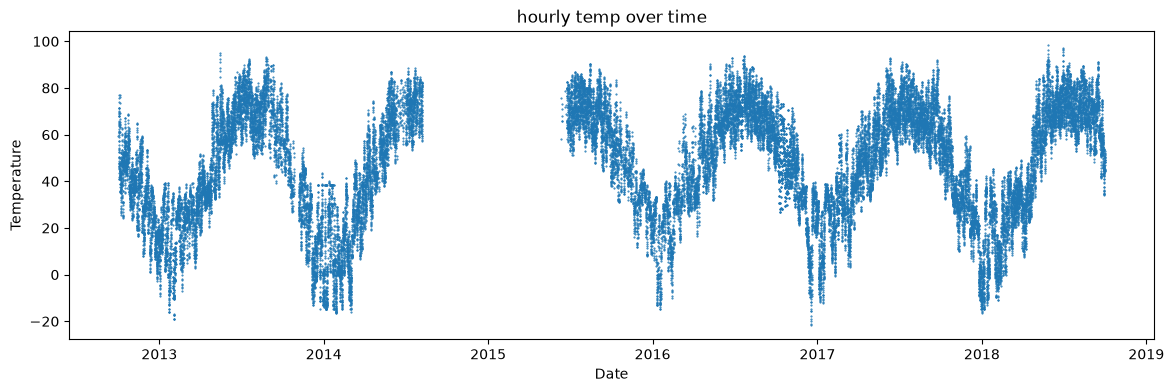

In [ ]:
#plotting temp over time to see if i can draw a conclusion
plt.figure(figsize=(14, 4))
plt.plot(data['date_time'], data['temp_f'], '.', markersize=1)
plt.title('hourly temp over time')
plt.xlabel('Date')
plt.ylabel('Temperature')
plt.show()